Luis Anunciacao, PhD
2026-10-15 - 21:40

# DA - AGEM Time Series

Loads `df.rds` from the DP notebook. Nothing is transformed here. Sections match the manuscript (`Results/AGEM - Time series manuscript.docx`): reliability (Measures), Table 1, Table 2, Figure 1, Figure 2.

**Items.** Stable items only (DP §3): 8 leader items (T1-T3) and 38 employee items (T1-T2), plus employee tenure. Companies A (FINX) and B (Xforce) are analysed together.

**Tables.** Counts by wave of the 3-category responses (header: respondents per wave); "—" = not tested. Items sorted by p; † = risk item (higher agreement or frequency = higher risk).

**Models (exploratory, no adjustment for multiplicity).** Each item: cumulative link (proportional odds) model of the 5-point `test_value` on wave, with company as a covariate because the share of each company differs across waves (`ordinal::clm`, logit link). p = likelihood ratio test of wave. OR = odds ratio of a higher response at the wave against T1, with Wald 95% CI. Post hoc (when p < .05): pairwise wave contrasts from the same model (`emmeans`, unadjusted); the column is dropped when no item in the table has p < .05. Waves are independent samples (no respondent ID).

## Packages and data

In [1]:
pacman::p_load(tidyverse, ordinal, emmeans, psych)

options(repr.matrix.max.rows = 400, repr.matrix.max.cols = 20)

# DP output from GitHub (Processing and analysis/Importable data/df.rds); token from the git credential store (gitcreds) when one exists,
# otherwise no token (works only while the repository is public)
df <- readRDS(gzcon(curl::curl("https://raw.githubusercontent.com/anovabr/AGEM-Time-Series/main/Processing%20and%20analysis/Importable%20data/df.rds",
                               handle = curl::new_handle() |> (\(h) tryCatch(curl::handle_setheaders(h, Authorization = paste("token", gitcreds::gitcreds_get()$password)), error = \(e) h))())))

In [2]:
# APA-style table for one instrument, companies pooled: item (English), 3-category response, counts by wave, p of wave (likelihood ratio test),
# odds ratio [95% CI] of each later wave against T1 and post hoc, from a proportional odds model of the 5-point response on wave + company
freq_table <- function(inst) {
  d <- filter(df, instrument == inst)
  attr(df, "options") |>
    filter(instrument == inst) |>
    distinct(item, code_3, response_3) |>
    inner_join(distinct(d, item, wave), by = "item", relationship = "many-to-many") |>
    left_join(count(d, item, code_3, wave), by = c("item", "code_3", "wave")) |>
    mutate(n = as.character(replace_na(n, 0L))) |>
    pivot_wider(names_from = wave, values_from = n, values_fill = "—", names_sort = TRUE) |>
    left_join(d |>
                filter(!is.na(test_value)) |>
                nest(.by = item) |>
                mutate(m = map(data, \(x) clm(ordered(test_value) ~ wave + company, data = x)),
                       p = map_dbl(m, \(m) drop1(m, test = "Chisq")["wave", "Pr(>Chi)"]),
                       or = map(m, \(m) exp(cbind(coef(m), confint(m, type = "Wald"))[grep("^wave", names(coef(m))), , drop = FALSE]) |>
                                  (\(o) set_names(sprintf("%.2f [%.2f, %.2f]", o[, 1], o[, 2], o[, 3]), paste("OR", sub("wave", "", rownames(o)))))() |>
                                  as.list() |> as_tibble()),
                       # post hoc: waves that differ (p < .05, unadjusted) when the omnibus p < .05, e.g. "T1 < T3"
                       post = map2_chr(m, p, \(m, p) if (p >= .05) "" else
                         emmeans(m, pairwise ~ wave, adjust = "none")$contrasts |>
                           as.data.frame() |>
                           filter(p.value < .05) |>
                           mutate(lab = map2_chr(str_split(contrast, " - "), estimate, \(w, e) paste(w[1], if (e < 0) "<" else ">", w[2]))) |>
                           pull(lab) |>
                           paste(collapse = "; "))) |>
                select(item, p, or, post) |>
                unnest(or),
              by = "item") |>
    left_join(distinct(d, item, item_en, risk), by = "item") |>
    arrange(p, item, code_3) |>
    mutate(first = code_3 == min(code_3), .by = item) |>
    transmute(Item = if_else(first, paste0(item, ". ", item_en, if_else(risk, " †", "")), ""),
              Response = paste0("(", code_3, ") ", response_3),
              across(matches("^T[123]$")),
              p = case_when(!first ~ "", is.na(p) ~ "—", p < .001 ~ "< .001", .default = sub("^0", "", sprintf("%.3f", p))),
              across(starts_with("OR"), \(x) if_else(first, replace_na(x, "—"), "")),
              `Post hoc` = if_else(first, replace_na(post, ""), "")) |>
    rename_with(\(w) paste0(w, " (n = ", table(distinct(d, wave, respondent_id)$wave)[w], ")"), matches("^T[123]$")) |>
    select(where(\(x) any(x != "")))   # drops Post hoc when no item has p < .05
}

# Reliability (Measures)

Cronbach's α by item set and wave, companies pooled: leader items .62 (T1), .78 (T2) and .32 (T3); symptoms (23 items) .92 and .90; work factors (14 items) .88 and .91.


In [3]:
# Cronbach's alpha by item set and wave, companies pooled; items aligned so that higher = more risk in the leader and symptom sets
# (work factor items share one direction); item 31 (satisfaction with oneself) belongs to neither set
df |>
  filter(!is.na(test_value), instrument == "lideres" | item != 31) |>
  mutate(set = case_when(instrument == "lideres" ~ "Leader items", item <= 30 ~ "Symptoms", .default = "Work factors"),
         value = if_else(risk | set == "Work factors", test_value, 6L - test_value)) |>
  reframe(n = n_distinct(respondent_id), items = n_distinct(item),
          # psych messages on smoothed correlation matrices are silenced; raw alpha is computed from the item covariances
          alpha = suppressWarnings(suppressMessages(alpha(pick(respondent_id, item, value) |> pivot_wider(names_from = item, values_from = value) |>
                                                            select(-respondent_id), warnings = FALSE)))$total$raw_alpha,
          .by = c(set, wave)) |>
  mutate(alpha = round(alpha, 2)) |>
  arrange(set, wave)

set,wave,n,items,alpha
<chr>,<chr>,<int>,<int>,<dbl>
Leader items,T1,21,8,0.62
Leader items,T2,22,8,0.78
Leader items,T3,18,8,0.32
Symptoms,T1,111,23,0.92
Symptoms,T2,105,23,0.90
Work factors,T1,111,14,0.88
Work factors,T2,102,14,0.91


# Table 1. Leaders

Leaders: 61 responses (T1 = 21, T2 = 22, T3 = 18; Company A 15, 16 and 15; Company B 6, 6 and 3). No item changed across the three waves (p from .192 to .822).


In [4]:
freq_table("lideres")

Item,Response,T1 (n = 21),T2 (n = 22),T3 (n = 18),p,OR T2,OR T3
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
7. I often need to intervene in conflicts that wear down my work routine. †,(1) disagree,13,15,8,.192,"0.67 [0.23, 2.01]","2.01 [0.64, 6.30]"
,(2) neutral,7,4,7,,,
,(3) agree,1,3,3,,,
"19. My work requires constant decisions that affect the safety, well being or performance of other people (e.g., reallocating people, giving difficult feedback, setting priorities). †",(1) disagree,7,10,6,.250,"0.40 [0.13, 1.27]","0.86 [0.28, 2.68]"
,(2) neutral,3,5,4,,,
,(3) agree,9,5,8,,,
9. I am satisfied with my team's overall performance.,(1) disagree,6,4,2,.290,"1.39 [0.46, 4.22]","2.61 [0.77, 8.88]"
,(2) neutral,1,2,1,,,
,(3) agree,13,16,15,,,


# Table 2. Employees

Employees: 216 responses (T1 = 111, T2 = 105; Company A 86 and 86; Company B 25 and 19). Freedom to organize one's activities (item 34; OR = 0.52) and encouragement to use creativity and knowledge (item 35; OR = 0.54) decreased from T1 to T2. The other 36 items did not change (p from .064 to .934).


In [5]:
freq_table("emocional")

Item,Response,T1 (n = 111),T2 (n = 105),p,OR T2,Post hoc
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"34. Are you free to organize your activities? (e.g., choosing the order of tasks)",(1) never or rarely,4,6,.012,"0.52 [0.31, 0.87]",T1 > T2
,(2) sometimes,10,19,,,
,(3) often or always,97,77,,,
"35. Are you encouraged to use your creativity and knowledge? (e.g., suggesting improvements or new ideas)",(1) never or rarely,8,10,.017,"0.54 [0.33, 0.90]",T1 > T2
,(2) sometimes,17,20,,,
,(3) often or always,86,72,,,
"31. Are you satisfied with yourself and your choices? (e.g., believing you are on the right path)",(1) never or rarely,8,13,.064,"0.62 [0.37, 1.03]",
,(2) sometimes,40,39,,,
,(3) often or always,63,50,,,


# Figure 1. Leaders: agreement by item and wave

Percentage of leaders agreeing (concordo parcialmente or concordo totalmente) with each stable item, by wave, companies pooled.


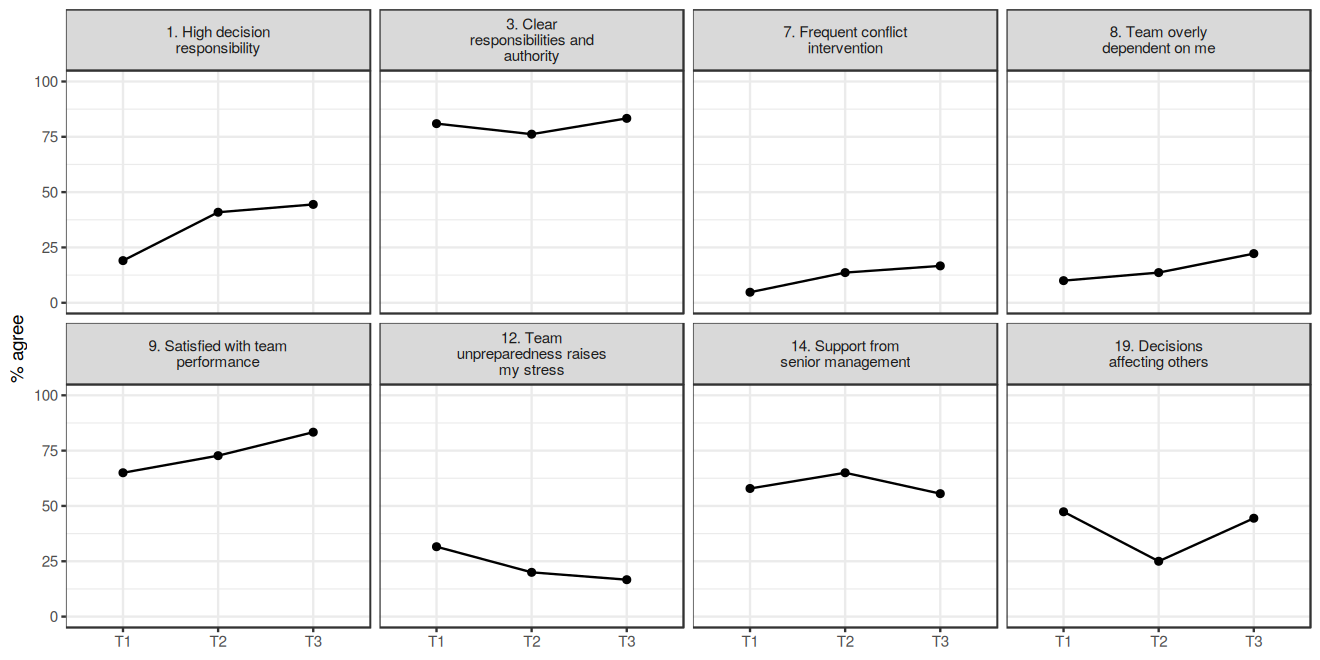

In [6]:
options(repr.plot.width = 11, repr.plot.height = 5.5)

df |>
  filter(instrument == "lideres") |>
  summarise(pct = 100 * mean(code_3 == 3), .by = c(item, label, wave)) |>
  mutate(label = fct_reorder(str_wrap(paste0(item, ". ", label), 22), item)) |>
  ggplot(aes(x = wave, y = pct, group = 1)) +
  geom_line() +
  geom_point() +
  facet_wrap(~ label, nrow = 2) +
  scale_y_continuous(limits = c(0, 100)) +
  labs(x = NULL, y = "% agree") +
  theme_bw()

# Figure 2. Employees: frequency by item and wave

Percentage of employees answering muitas vezes or sempre (often or always) to each stable item, by wave, companies pooled.


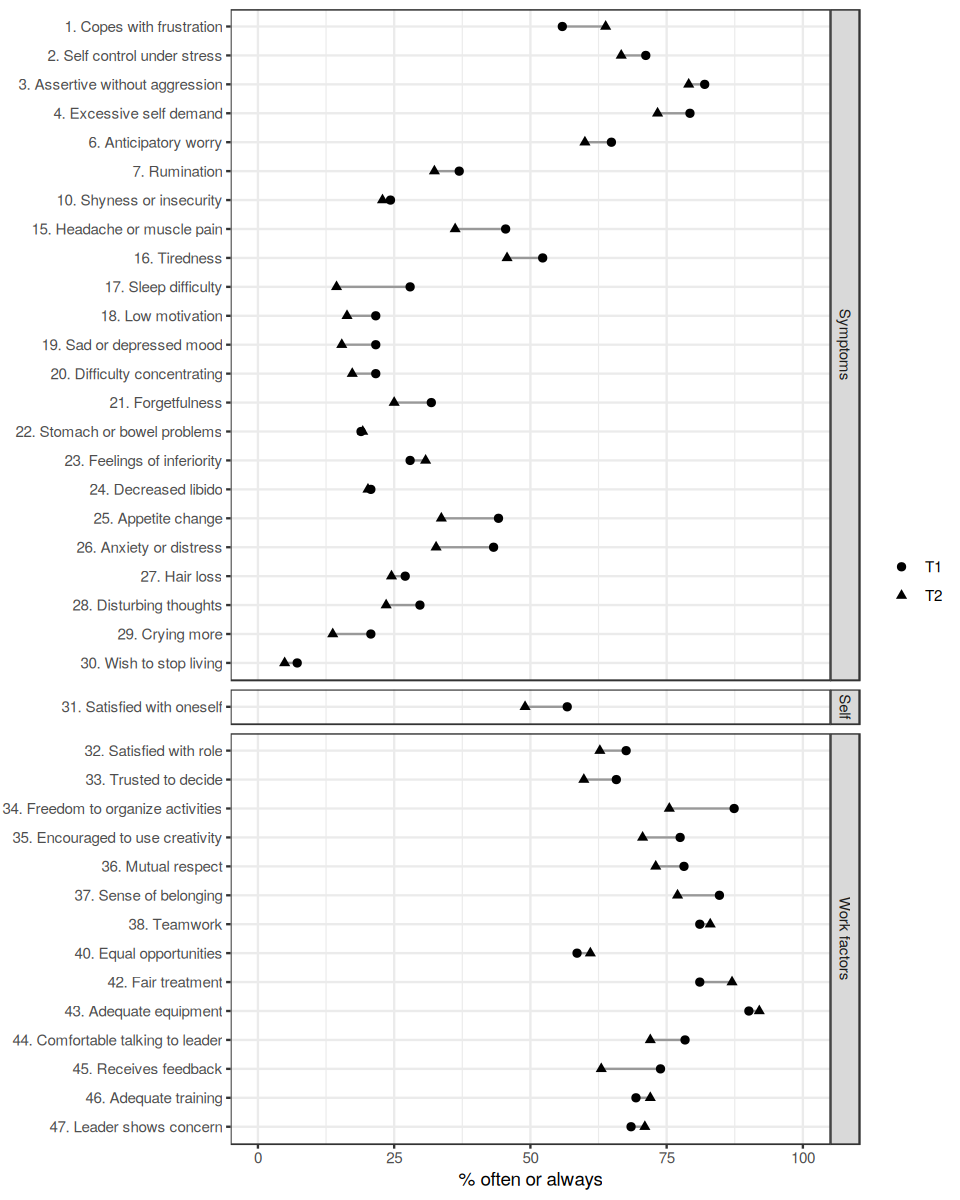

In [7]:
options(repr.plot.width = 8, repr.plot.height = 10)

df |>
  filter(instrument == "emocional", item != 57) |>
  summarise(pct = 100 * mean(code_3 == 3), .by = c(item, label, wave)) |>
  mutate(label = fct_reorder(paste0(item, ". ", label), -item),
         domain = factor(case_when(item <= 30 ~ "Symptoms", item == 31 ~ "Self", .default = "Work factors"), levels = c("Symptoms", "Self", "Work factors"))) |>
  ggplot(aes(x = pct, y = label, shape = wave)) +
  geom_line(aes(group = label), colour = "grey60") +
  geom_point(size = 2) +
  facet_grid(domain ~ ., scales = "free_y", space = "free_y") +
  scale_x_continuous(limits = c(0, 100)) +
  labs(x = "% often or always", y = NULL, shape = NULL) +
  theme_bw()